# Control óptimo de EDOs — Clase 3
**Costo final, condiciones en T y existencia**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

## 1. Tumor: $\min x(T)+\int_0^T u^2$, $\dot x=\alpha x-u$
Transversalidad: $\lambda(T)=\phi'(x(T))=-1$.

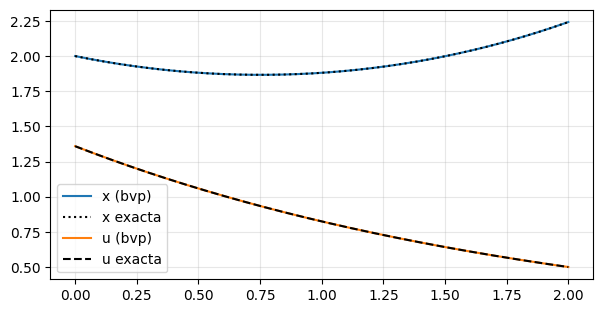

In [3]:
al, T, x0 = 0.5, 2.0, 2.0
sistema = lambda t, y: np.vstack([al*y[0] + y[1]/2, -al*y[1]])     # u = -lam/2
bordes = lambda ya, yb: np.array([ya[0] - x0, yb[1] + 1])
t = np.linspace(0, T, 40)
sol = solve_bvp(sistema, bordes, t, np.zeros((2, t.size)))
tt = np.linspace(0, T, 300)
x_ex = x0*np.exp(al*tt) + np.exp(al*T)*(np.exp(-al*tt) - np.exp(al*tt))/(4*al)
plt.plot(tt, sol.sol(tt)[0], label='x (bvp)'); plt.plot(tt, x_ex, 'k:', label='x exacta')
plt.plot(tt, -sol.sol(tt)[1]/2, label='u (bvp)'); plt.plot(tt, np.exp(al*(T - tt))/2, 'k--', label='u exacta')
plt.legend(); plt.show()

## 2. Restricción final $x(T)\le M$: tiro sobre el multiplicador $\beta$
Problema: $\min\int_0^T u^2$, $\dot x = ax-u$, $x(T)\le M$. Con $\lambda(T)=-\beta$ resulta $u=\frac\beta2e^{a(T-t)}$.
Buscamos $\beta\ge 0$ con `brentq` tal que $x(T)=M$, y comparamos con la fórmula cerrada.

In [4]:
a, T, x0 = 0.5, 2.0, 1.0
def xT(beta):
    s = solve_ivp(lambda t, x: a*x - beta/2*np.exp(a*(T - t)), [0, T], [x0], rtol=1e-10)
    return s.y[0, -1]
for M in [2.5, 2.0, 1.5, 1.0, 3.0]:
    if xT(0) <= M:
        beta = 0.0           # restricción inactiva
    else:
        beta = brentq(lambda b: xT(b) - M, 0, 50)
    formula = max(0, 4*a*(x0*np.exp(a*T) - M)/(np.exp(2*a*T) - 1))
    print(f'M={M}: beta (tiro) = {beta:.6f}   beta (fórmula) = {formula:.6f}')

M=2.5: beta (tiro) = 0.068330   beta (fórmula) = 0.068330
M=2.0: beta (tiro) = 0.224848   beta (fórmula) = 0.224848
M=1.5: beta (tiro) = 0.381365   beta (fórmula) = 0.381365
M=1.0: beta (tiro) = 0.537883   beta (fórmula) = 0.537883
M=3.0: beta (tiro) = 0.000000   beta (fórmula) = 0.000000


## 3. Chattering: $J(u_k)\to 0$ pero no hay óptimo
$\min\int_0^1 x^2+(1-u^2)^2$, $\dot x=u$, $|u|\le1$, con $u_k=\pm1$ alternando cada $1/(2k)$.

In [5]:
t = np.linspace(0, 1, 200001)
for k in [1, 2, 4, 8, 16, 32]:
    u = np.where(np.floor(2*k*t) % 2 == 0, 1.0, -1.0)
    x = np.concatenate([[0], np.cumsum(0.5*(u[1:] + u[:-1])*np.diff(t))])
    J = integral(x**2 + (1 - u**2)**2, t)
    print(f'k={k:3d}  J(u_k)={J:.3e}   1/(12k^2)={1/(12*k**2):.3e}')

k=  1  J(u_k)=8.333e-02   1/(12k^2)=8.333e-02
k=  2  J(u_k)=2.083e-02   1/(12k^2)=2.083e-02
k=  4  J(u_k)=5.208e-03   1/(12k^2)=5.208e-03
k=  8  J(u_k)=1.302e-03   1/(12k^2)=1.302e-03
k= 16  J(u_k)=3.254e-04   1/(12k^2)=3.255e-04
k= 32  J(u_k)=8.134e-05   1/(12k^2)=8.138e-05


## 4. Primer *sweep*: bacterias
$\max Cx(1)-\int_0^1u^2$, $\dot x=rx+Aux-Bu^2e^{-x}$.
PMP: $\dot\lambda=-\lambda(r+Au+Bu^2e^{-x})$, $\lambda(1)=C$, $u=\dfrac{\lambda Ax}{2(1+\lambda Be^{-x})}$.
(En la Clase 4 explicamos el algoritmo `fbsm` en detalle.)

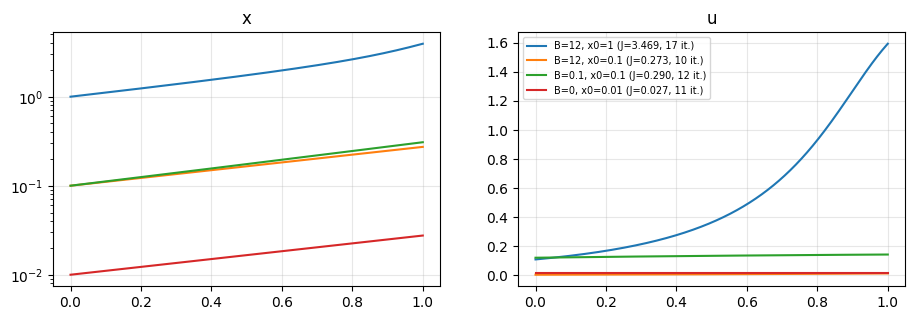

In [6]:
casos = [(1, 1, 12, 1, 1), (1, 1, 12, 1, 0.1), (1, 1, 0.1, 1, 0.1), (1, 1, 0, 1, 0.01)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for (r, A, B, C, x0) in casos:
    res = fbsm(lambda t, x, u: r*x + A*u*x - B*u**2*np.exp(-x),
               lambda t, x, u, l: -l*(r + A*u + B*u**2*np.exp(-x)),
               lambda t, x, l: l*A*x/(2*(1 + l*B*np.exp(-x))),
               x0, lambda xT: np.array([C]), 1.0)
    J = C*res['x'][-1, 0] - integral(res['u'][:, 0]**2, res['t'])
    lab = f'B={B}, x0={x0} (J={J:.3f}, {res["iters"]} it.)'
    ax[0].plot(res['t'], res['x'][:, 0], label=lab); ax[1].plot(res['t'], res['u'][:, 0], label=lab)
ax[0].set_yscale('log'); ax[0].set_title('x'); ax[1].set_title('u'); ax[1].legend(fontsize=7); plt.show()

**Ejercicio 5 de la clase** ($B=0$): $u^*$ es constante y cumple $u=\frac{ACx_0}{2}e^{(r+Au)T}$.

In [7]:
r, A, C, x0, T = 1, 1, 1, 0.01, 1
u_const = brentq(lambda u: u - A*C*x0/2*np.exp((r + A*u)*T), 0, 1)
print('u constante (ecuación):', u_const)

u constante (ecuación): 0.013779995065578029


## Para explorar
1. En la sección 2, graficar el costo óptimo $\int u^2$ contra $M$ y su derivada numérica; comparar con $-\beta$.
2. Bacterias: ¿qué pasa si $C$ es 10 veces más grande? Interpretar.